<a href="https://colab.research.google.com/github/sahilmane69/Image-Pixel-Manipulator/blob/main/imageproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

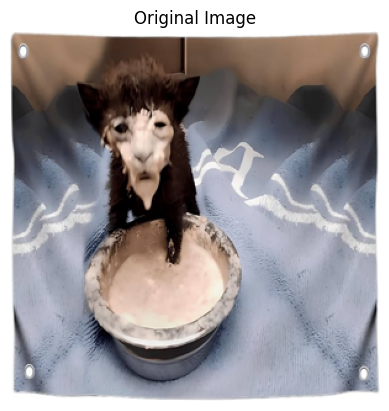

In [14]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

path = "image.jpg"

img = Image.open(path).convert("RGB")
img = img.resize((300, 300))
img = np.array(img, dtype=np.uint8)

plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

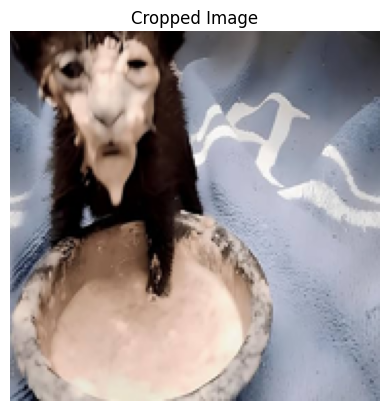

In [3]:
crop = img[60:240, 60:240]

plt.imshow(crop)
plt.title("Cropped Image")
plt.axis("off")
plt.show()

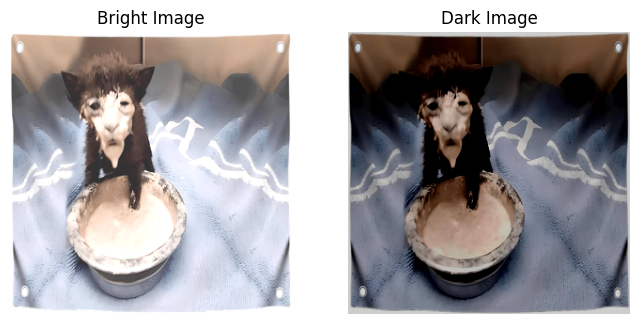

In [4]:
bright = img.astype(np.float32) + 50
bright = np.clip(bright, 0, 255).astype(np.uint8)

dark = img.astype(np.float32) - 50
dark = np.clip(dark, 0, 255).astype(np.uint8)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(bright)
plt.title("Bright Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(dark)
plt.title("Dark Image")
plt.axis("off")

plt.show()

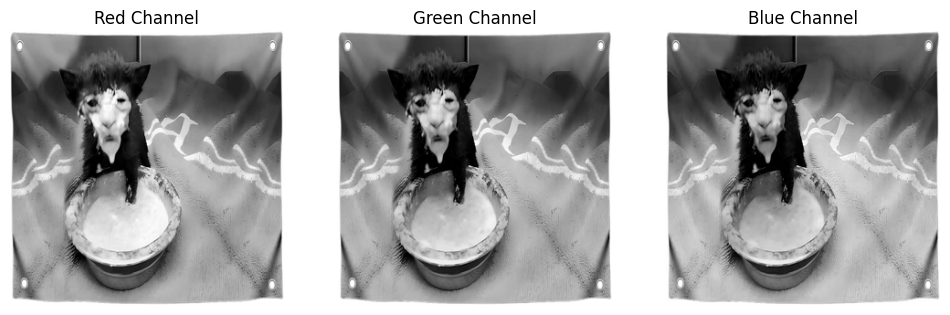

In [5]:
red = img[:, :, 0]
green = img[:, :, 1]
blue = img[:, :, 2]

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(red, cmap="gray")
plt.title("Red Channel")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(green, cmap="gray")
plt.title("Green Channel")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(blue, cmap="gray")
plt.title("Blue Channel")
plt.axis("off")

plt.show()

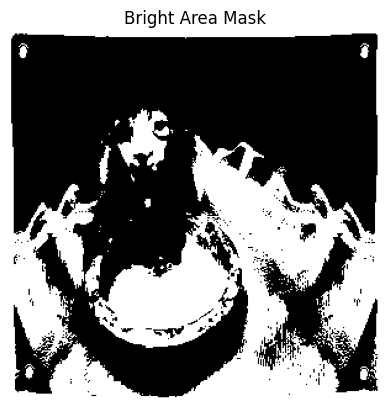

In [6]:
gray = img.mean(axis=2)
mask = gray > 170

plt.imshow(mask, cmap="gray")
plt.title("Bright Area Mask")
plt.axis("off")
plt.show()

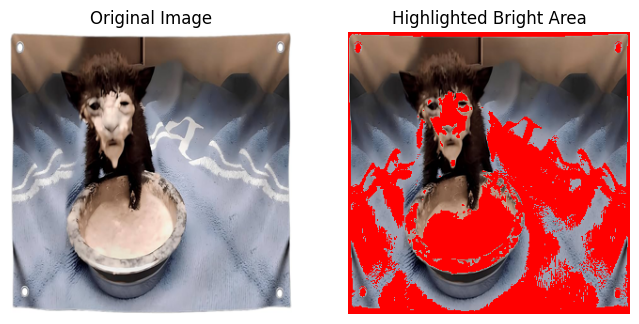

In [7]:
highlight = img.copy()
highlight[mask] = [255, 0, 0]

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(highlight)
plt.title("Highlighted Bright Area")
plt.axis("off")

plt.show()

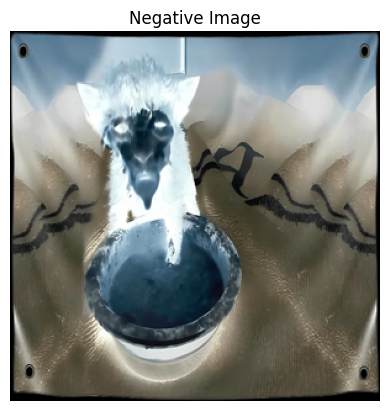

In [9]:
negative = 255 - img

plt.imshow(negative)
plt.title("Negative Image")
plt.axis("off")
plt.show()

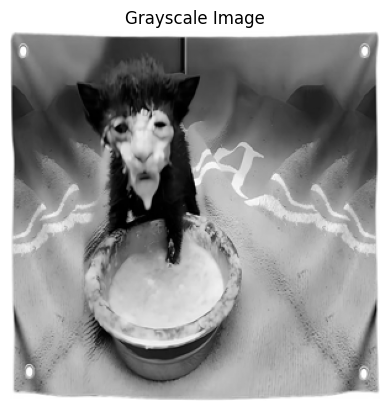

In [10]:
gray = img.mean(axis=2).astype(np.uint8)

plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

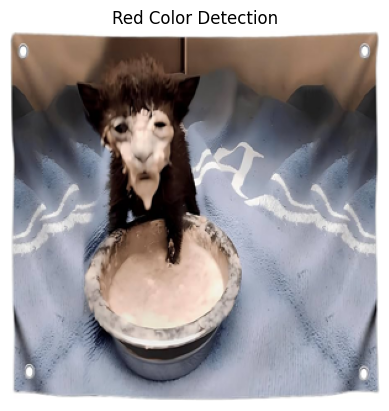

In [11]:
red_mask = (img[:, :, 0] > 150) & (img[:, :, 1] < 100) & (img[:, :, 2] < 100)

red_detect = img.copy()
red_detect[red_mask] = [255, 255, 255]

plt.imshow(red_detect)
plt.title("Red Color Detection")
plt.axis("off")
plt.show()

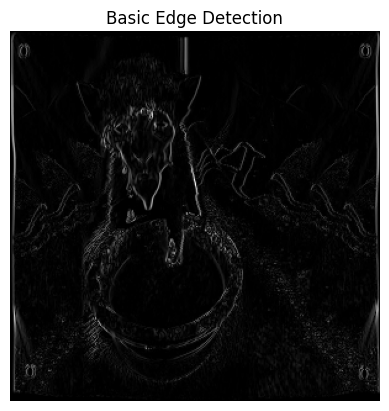

In [12]:
gray = img.mean(axis=2)

edge = np.zeros_like(gray)
edge[:, 1:] = np.abs(gray[:, 1:] - gray[:, :-1])

plt.imshow(edge, cmap="gray")
plt.title("Basic Edge Detection")
plt.axis("off")
plt.show()

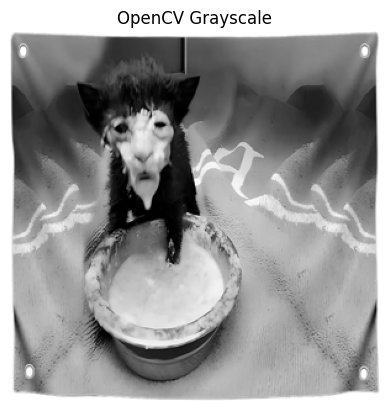

In [17]:
gray_cv = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

plt.imshow(gray_cv, cmap="gray")
plt.title("OpenCV Grayscale")
plt.axis("off")
plt.show()

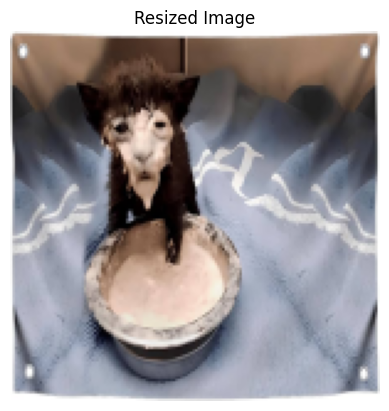

In [18]:
small = cv2.resize(img, (150, 150))

plt.imshow(small)
plt.title("Resized Image")
plt.axis("off")
plt.show()

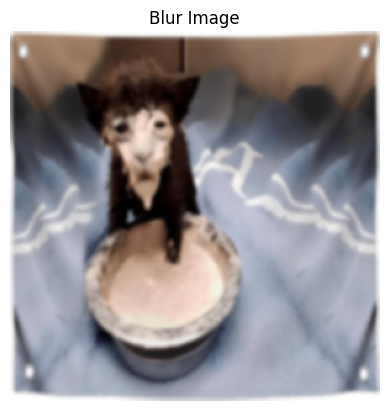

In [19]:
blur = cv2.GaussianBlur(img, (7, 7), 0)

plt.imshow(blur)
plt.title("Blur Image")
plt.axis("off")
plt.show()

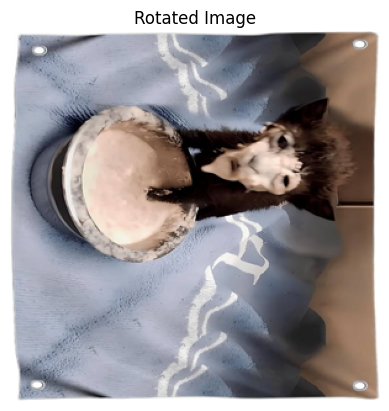

In [20]:
rotate = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)

plt.imshow(rotate)
plt.title("Rotated Image")
plt.axis("off")
plt.show()

In [8]:
print("shape:", img.shape)
print("dtype:", img.dtype)
print("min:", img.min())
print("max:", img.max())

assert img.shape == (300, 300, 3)
assert img.dtype == np.uint8
assert img.min() >= 0
assert img.max() <= 255
assert crop.shape == (180, 180, 3)
assert mask.shape == (300, 300)

print("Real image processing done")

shape: (300, 300, 3)
dtype: uint8
min: 0
max: 255
Real image processing done
